In [1]:
# ====================================================
# Libraries
# ====================================================

import numpy as np
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

In [2]:
# ====================================================
# File paths
# ====================================================

# Update the paths below to match your local clone
fname_noFRB = "/home/brunowesley/projetos/MCMC-cosmo/Codes/MCMC-Models/MG-based/Hu-Sawicki/CC_SNe_BAO/flat_samples_HS_n1_cc_sne_bao.npy"
fname_FRB   = "/home/brunowesley/projetos/MCMC-cosmo/Codes/MCMC-Models/MG-based/Hu-Sawicki/CC_SNe_BAO_FRB/flat_samples_HS_n1_cc_sne_bao_frb.npy"


# ====================================================
# Load samples (FULL chains)
# ====================================================

samples_noFRB_full = np.load(fname_noFRB)
samples_FRB_full   = np.load(fname_FRB)

print("No FRB (full):", samples_noFRB_full.shape)
print("With FRB (full):", samples_FRB_full.shape)

No FRB (full): (1592520, 5)
With FRB (full): (2785440, 7)


In [3]:
# ====================================================
# Function: marginalized statistics (PRINT + SAVE)
# ====================================================

def print_stats(flat_samples, param_names_indices, fmt_map, title, file=None):

    lines = []
    lines.append("\n" + "="*60)
    lines.append(f"{title:^60}")
    lines.append("="*60)

    for name, idx in param_names_indices:
        samples = flat_samples[:, idx]

        median  = np.percentile(samples, 50)
        lower68 = np.percentile(samples, 16)
        upper68 = np.percentile(samples, 84)
        lower95 = np.percentile(samples, 2.5)
        upper95 = np.percentile(samples, 97.5)

        ep68 = upper68 - median
        em68 = median  - lower68
        ep95 = upper95 - median
        em95 = median  - lower95

        fmt = fmt_map.get(name, ".3f")

        lines.append(f"\n  {name}:")
        lines.append(f"    {median:{fmt}} +{ep68:{fmt}} -{em68:{fmt}}  (68% CL)")
        lines.append(f"    {median:{fmt}} +{ep95:{fmt}} -{em95:{fmt}}  (95% CL)")

    lines.append("\n" + "="*60)

    for line in lines:
        print(line)

    if file is not None:
        for line in lines:
            file.write(line + "\n")


# ====================================================
# Save ALL output
# ====================================================

output_file = "stats_HS_n1_full.txt"

with open(output_file, "w", encoding="utf-8") as f:

    # ====================================================
    # WITHOUT FRB
    # ====================================================

    param_noFRB = [
        ("H0", 0),
        ("Om0", 1),
        ("Ob", 2),
        ("MB", 3),
        ("mu_HS", 4)
    ]

    fmt_noFRB = {
        "H0": ".2f",
        "Om0": ".3f",
        "Ob": ".4f",
        "MB": ".3f",
        "mu_HS": ".2f"
    }

    print_stats(
        samples_noFRB_full,
        param_noFRB,
        fmt_noFRB,
        "HS | CC + SNe + BAO",
        file=f
    )

    # ====================================================
    # WITH FRB
    # ====================================================

    param_FRB = [
        ("H0", 0),
        ("Om0", 1),
        ("Ob", 2),
        ("MB", 3),
        ("mu_HS", 4),
        ("sigma_host", 5),
        ("exp_mu", 6)
    ]

    fmt_FRB = {
        "H0": ".2f",
        "Om0": ".3f",
        "Ob": ".4f",
        "MB": ".3f",
        "mu_HS": ".2f",
        "sigma_host": ".3f",
        "exp_mu": ".1f"
    }

    print_stats(
        samples_FRB_full,
        param_FRB,
        fmt_FRB,
        "HS | CC + SNe + BAO + FRB",
        file=f
    )

print(f"\n✅ Full output saved to: {output_file}")


                    HS | CC + SNe + BAO                     

  H0:
    69.69 +1.60 -1.59  (68% CL)
    69.69 +3.16 -3.12  (95% CL)

  Om0:
    0.284 +0.011 -0.011  (68% CL)
    0.284 +0.022 -0.021  (95% CL)

  Ob:
    0.0502 +0.0029 -0.0028  (68% CL)
    0.0502 +0.0057 -0.0053  (95% CL)

  MB:
    -19.412 +0.048 -0.049  (68% CL)
    -19.412 +0.094 -0.097  (95% CL)

  mu_HS:
    74.59 +16.55 -17.45  (68% CL)
    74.59 +32.98 -37.60  (95% CL)


                 HS | CC + SNe + BAO + FRB                  

  H0:
    70.32 +1.03 -1.05  (68% CL)
    70.32 +2.00 -2.08  (95% CL)

  Om0:
    0.282 +0.010 -0.010  (68% CL)
    0.282 +0.021 -0.020  (95% CL)

  Ob:
    0.0514 +0.0017 -0.0017  (68% CL)
    0.0514 +0.0033 -0.0034  (95% CL)

  MB:
    -19.396 +0.036 -0.036  (68% CL)
    -19.396 +0.070 -0.072  (95% CL)

  mu_HS:
    77.54 +15.68 -16.24  (68% CL)
    77.54 +31.21 -33.76  (95% CL)

  sigma_host:
    0.857 +0.132 -0.109  (68% CL)
    0.857 +0.283 -0.197  (95% CL)

  exp_mu:
    96.7 +1

Removed no burn in
Removed no burn in


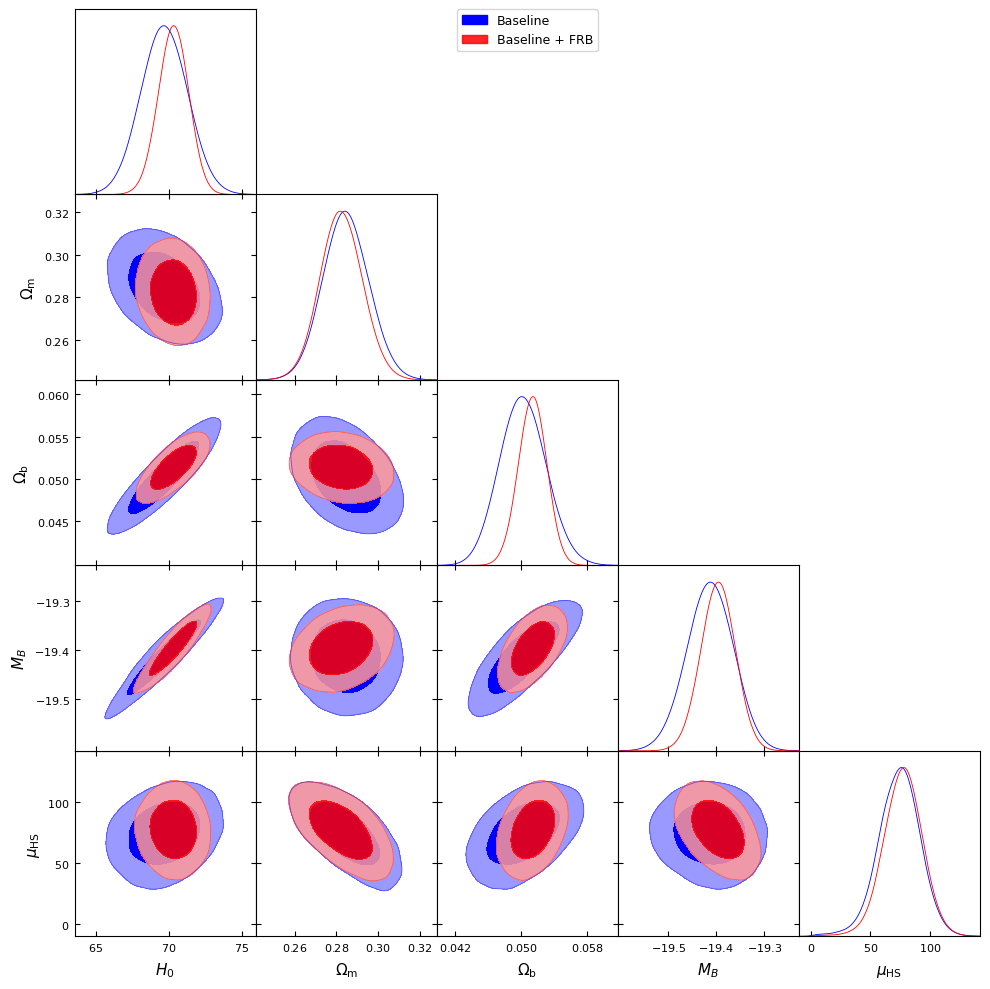

In [4]:
# ====================================================
# Parameters for corner plot
# ====================================================

idx = [0, 1, 2, 3, 4]

samples_noFRB = samples_noFRB_full[:, idx]
samples_FRB   = samples_FRB_full[:, idx]

param_names  = ["H0", "Om0", "Ob", "MB", "mu_HS"]
param_labels = [r"H_0", r"\Omega_{\rm m}", r"\Omega_{\rm b}", r"M_B", r"\mu_{\rm HS}"]


# ====================================================
# GetDist
# ====================================================

gd_noFRB = MCSamples(samples=samples_noFRB,
                     names=param_names,
                     labels=param_labels)

gd_FRB   = MCSamples(samples=samples_FRB,
                     names=param_names,
                     labels=param_labels)

for gd in [gd_noFRB, gd_FRB]:
    gd.updateSettings({
        "smooth_scale_1D": 0.25,
        "smooth_scale_2D": 0.25,
        "fine_bins": 1024,
        "fine_bins_2D": 1024,
    })


# ====================================================
# Corner plot
# ====================================================

g = plots.get_subplot_plotter()

g.triangle_plot(
    [gd_noFRB, gd_FRB],
    filled=True,
    legend_labels=[r"Baseline", r"Baseline + FRB"],
    contour_colors=["blue", "red"],
    title_limit=0
)

plt.savefig("Corner_HS_n1_comparison.png", dpi=300, bbox_inches="tight")
plt.savefig("Corner_HS_n1_comparison.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
# ====================================================
# Derived parameter: sound horizon rd
# ====================================================

Neff = 3.046 

def compute_rd_chain(flat_samples):
    H0  = flat_samples[:, 0]
    Om0 = flat_samples[:, 1]
    Ob  = flat_samples[:, 2]

    h2   = (H0 / 100.0)**2
    Obh2 = Ob * h2
    Omh2 = Om0 * h2

    rd = 147.05 * ((Obh2 / 0.02236)**-0.13) \
                 * ((Omh2 / 0.1432)**-0.23) \
                 * ((Neff  / 3.04)**-0.1)

    return rd


def print_rd_stats(rd_chain, title):

    median  = np.percentile(rd_chain, 50)
    lower68 = np.percentile(rd_chain, 16)
    upper68 = np.percentile(rd_chain, 84)
    lower95 = np.percentile(rd_chain, 2.5)
    upper95 = np.percentile(rd_chain, 97.5)

    ep68 = upper68 - median
    em68 = median  - lower68
    ep95 = upper95 - median
    em95 = median  - lower95

    print("\n" + "="*60)
    print(f"{title:^60}")
    print("="*60)

    print(f"\n  r_d:")
    print(f"    {median:.3f} +{ep68:.3f} -{em68:.3f}  (68% CL)")
    print(f"    {median:.3f} +{ep95:.3f} -{em95:.3f}  (95% CL)")

    print("\n" + "="*60)


# ====================================================
# Compute rd
# ====================================================

rd_noFRB = compute_rd_chain(samples_noFRB_full)
rd_FRB   = compute_rd_chain(samples_FRB_full)

print_rd_stats(rd_noFRB, "Sound Horizon r_d | CC + SNe + BAO")
print_rd_stats(rd_FRB,   "Sound Horizon r_d | CC + SNe + BAO + FRB")


             Sound Horizon r_d | CC + SNe + BAO             

  r_d:
    146.602 +3.251 -3.118  (68% CL)
    146.602 +6.521 -6.013  (95% CL)


          Sound Horizon r_d | CC + SNe + BAO + FRB          

  r_d:
    145.478 +2.273 -2.204  (68% CL)
    145.478 +4.590 -4.255  (95% CL)

